# Capítulo 5 · Proyecto 1: comparación de modelos

> ¿Qué modelo recomendarías para clasificar la presencia de enfermedad cardiaca y qué resultados respaldan tu elección?

Utiliza el dataset [UCI Heart Disease de Kaggle](https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data), archivo `heart_disease_uci.csv`, y documenta tu trabajo en un notebook reproducible.

## Etapa 1: limpieza y preparación

1. Identifica los valores faltantes y los valores inválidos, decide cómo tratarlos y justifica brevemente tu decisión.
2. Explora los posibles outliers y explica si los conservarás o aplicarás algún tratamiento.
3. Prepara las variables numéricas y categóricas. Crea el objetivo binario (**target**) a partir de `num`: **target = 0 si num = 0** (ausencia de enfermedad) y **target = 1 si num es 1, 2, 3 o 4** (presencia de enfermedad). Excluye tanto `num` como el target de las entradas del modelo.

In [ ]:
from pathlib import Path

import kagglehub
from kagglehub import KaggleDatasetAdapter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder,
    RobustScaler,
    StandardScaler,
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

file_path = "heart_disease_uci.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "redwankarimsony/heart-disease-data",
    file_path,
)

raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()),
    Path.cwd(),
)
DATA_DIR = raiz / "data"
DATA_DIR.mkdir(exist_ok=True)
df.to_csv(DATA_DIR / "heart_disease_uci.csv", index=False)

print(f"Dimensiones del dataset: {df.shape}")
df.head()




100%|██████████| 77.5k/77.5k [00:00<00:00, 990kB/s]


Dimensiones del dataset: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [5]:
nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({"Nulos": nulos, "Porcentaje (%)": porcentaje})

print("=== VALORES FALTANTES ===")
display(resumen_nulos[resumen_nulos["Nulos"] > 0])

print("\n=== VALORES INVÁLIDOS (CEROS CLÍNICOS) ===")
print(f"Registros con trestbps == 0: {(df['trestbps'] == 0).sum()}")
print(f"Registros con chol == 0:     {(df['chol'] == 0).sum()}")


=== VALORES FALTANTES ===


,Nulos,Porcentaje (%)
trestbps,59,6.41
chol,30,3.26
fbs,90,9.78
restecg,2,0.22
thalch,55,5.98
exang,55,5.98
oldpeak,62,6.74
slope,309,33.59
ca,611,66.41
thal,486,52.83



=== VALORES INVÁLIDOS (CEROS CLÍNICOS) ===
Registros con trestbps == 0: 1
Registros con chol == 0:     172


,age,trestbps,chol,thalch,oldpeak,ca
count,920.00,860.00,718.00,865.00,858.00,309.00
mean,53.51,132.29,246.83,137.55,0.88,0.68
std,9.42,18.54,58.53,25.93,1.09,0.94
min,28.00,80.00,85.00,60.00,-2.60,0.00
25%,47.00,120.00,210.00,120.00,0.00,0.00
50%,54.00,130.00,239.50,140.00,0.50,0.00
75%,60.00,140.00,276.75,157.00,1.50,1.00
max,77.00,200.00,603.00,202.00,6.20,3.00


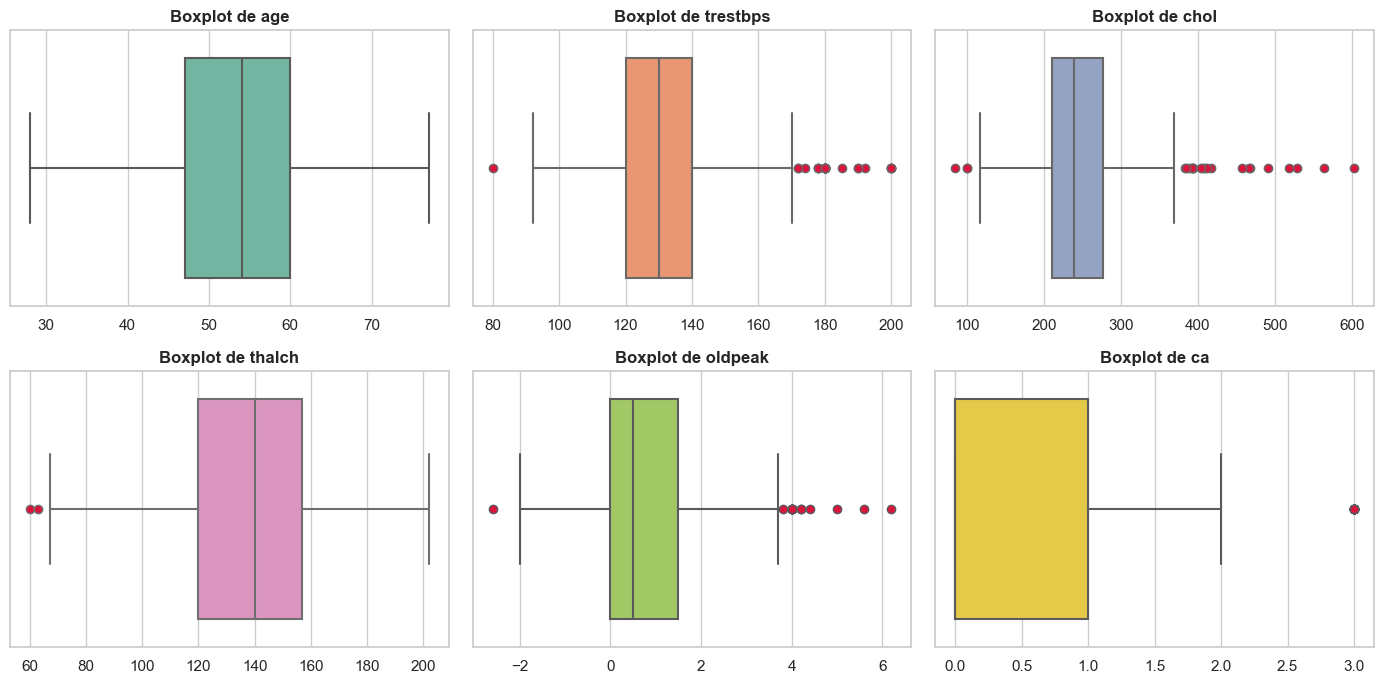

In [7]:
df_temp = df.copy()
df_temp["trestbps"] = df_temp["trestbps"].replace(0, np.nan)
df_temp["chol"] = df_temp["chol"].replace(0, np.nan)

num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
display(df_temp[num_cols].describe().round(2))

# Tablas
colores = sns.color_palette("Set2", n_colors=len(num_cols))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col, color in zip(axes.flatten(), num_cols, colores):
    sns.boxplot(
        x=df_temp[col],
        ax=ax,
        color=color,
        flierprops={"marker": "o", "markerfacecolor": "crimson", "markersize": 6},
    )
    ax.set_title(f"Boxplot de {col}", fontsize=12, fontweight="bold")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()



In [ ]:
df_clean = df.copy()

# 1. Reemplazar imposibles por NaN
df_clean["trestbps"] = df_clean["trestbps"].replace(0, np.nan)
df_clean["chol"] = df_clean["chol"].replace(0, np.nan)

# 2. variable sano o enfermo
df_clean["target"] = (df_clean["num"] > 0).astype(int)
print("Distribución de clases en target:")
print(df_clean["target"].value_counts())
print("\nProporción (%):")
print((df_clean["target"].value_counts(normalize=True) * 100).round(2))

# 3. Separar X e y (excluyendo id, num y target)
X = df_clean.drop(columns=["id", "num", "target"])
y = df_clean["target"]

# 4. División Train / Test estratificada (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# 5. Definir columnas y pipeline de preprocesamiento
num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
cat_cols = ["sex", "dataset", "cp", "fbs", "restecg", "exang", "slope", "thal"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols),
])

# Verificar cómo queda X_train ya transformado
X_train_prep = preprocessor.fit_transform(X_train)
print(f"\nDimensiones de X_train tras preprocesamiento: {X_train_prep.shape}")
X_train_prep.head()


Distribución de clases en target:
target
1    509
0    411
Name: count, dtype: int64

Proporción (%):
target
1    55.33
0    44.67
Name: proportion, dtype: float64

Dimensiones de X_train tras preprocesamiento: (736, 21)


,num__age,num__trestbps,num__chol,num__thalch,num__oldpeak,num__ca,cat__sex_Male,cat__dataset_Hungary,cat__dataset_Switzerland,cat__dataset_VA Long Beach,...,cat__cp_non-anginal,cat__cp_typical angina,cat__fbs_True,cat__restecg_normal,cat__restecg_st-t abnormality,cat__exang_True,cat__slope_flat,cat__slope_upsloping,cat__thal_normal,cat__thal_reversable defect
640,-0.076923,1.50,0.000000,-0.514286,-0.333333,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
743,1.538462,0.00,0.000000,0.000000,0.000000,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
890,-0.076923,-0.30,0.079602,-0.514286,1.000000,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
270,0.538462,0.50,-0.636816,-0.057143,0.933333,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
654,0.153846,1.25,0.000000,-1.171429,-0.333333,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
